<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

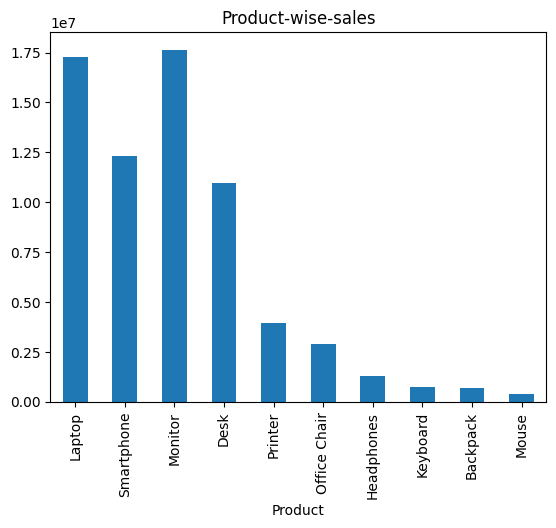

In [ ]:
# from google.colab import files
# uploaded = files.upload()
import pandas as pd
df = pd.read_csv("ecommerce_sales_raw.csv")

df.head()
df.shape
df.columns
df.info()
df.isnull().sum()
df.duplicated().sum()
df = df.drop_duplicates()
df.isnull().sum()
df["City"].mode()
df["Payment_Method"].mode()
df["Customer_Type"].mode()

df["City"] = df["City"].fillna(df["City"].mode()[0])
df.isnull().sum()
df["Payment_Method"] = df["Payment_Method"].fillna(df["Payment_Method"].mode()[0])
df.isnull().sum()
df["Customer_Type"] = df["Customer_Type"].fillna(df["Customer_Type"].mode()[0])
df.isnull().sum()
df.dtypes
df["Order_Date"] = pd. to_datetime(df["Order_Date"])
df.info()
df["Sales"].sum()
round(df["Profit"].sum())
df["Quantity"].sum()
df["Order_ID"].nunique()
round(df["Sales"].sum() / df["Order_ID"].nunique())
round(df.groupby("Region")["Sales"].sum())
round(df.groupby("Region") ["Profit"].sum())
round(df.groupby("Product") ["Sales"].sum().sort_values(ascending=False))
round(df.groupby("Product") ["Profit"].sum().sort_values(ascending=True))
round(df.groupby("Category")["Sales"].sum().sort_values(ascending=False))
round(df.groupby("Customer_Type")["Sales"].sum().sort_values(ascending=False))
round(df.groupby("Payment_Method")["Sales"].sum().sort_values(ascending=False))
round(df.groupby("City")["Sales"].sum().sort_values(ascending=False))
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df.dtypes
# “Which month generated the highest sales?”
df.groupby(df["Order_Date"].  dt.to_period("M"))["Sales"].sum()
# Month wise total profit caluclation
df.groupby(df["Order_Date"].dt.to_period("M"))["Profit"].sum()
# who are our top 10 customer by sales?
df.groupby("Customer_Name")["Sales"].sum().sort_values(ascending=False).head(10)
# who are our top 10 customer by profit?
df.groupby("Customer_Name")["Profit"].sum().sort_values(ascending=False).head(10)
df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100
df["Profit_Margin"].head()
df.groupby("Category")["Profit"].sum().sort_values(ascending=False)
# “Which cities generate the highest sales?”
df.groupby("City")["Sales"].sum().sort_values(ascending=False)
#   Which cities generate the highest profit?”
df.groupby ("City")["Profit"].sum().sort_values(ascending=False)
# “Which type of customers contributes the most profit?”
df.groupby("Customer_Type")["Profit"].sum().sort_values(ascending=False)
# “Which payment method is used for the highest number of orders?”
df.groupby("Payment_Method")["Order_ID"].nunique().sort_values(ascending=False)
# “Which product category generates the highest sales?
df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
# “Which product category generates the highest profit?”
df.groupby("Category")["Profit"].sum().sort_values(ascending=False)
# who are top 10 customers by sales
df.groupby("Customer_Name")["Sales"].sum().sort_values(ascending=False).head(10)
#“Who are our top 10 most profitable customers?”
df.groupby("Customer_Name")["Profit"].sum().sort_values(ascending=False).head(10)
# “Which month generated the highest sales?”
df.groupby(df["Order_Date"].dt.to_period("M")) ["Sales"].sum().sort_values(ascending=False)
# "Which month generated the hidgest profit?"
df.groupby(df["Order_Date"].dt.to_period("M")) ["Profit"].sum().sort_values(ascending=False)
# Which month had the highest number of orders?
df.groupby(df["Order_Date"].dt.to_period("M")) ["Order_ID"].nunique().sort_values(ascending=False)
# “Which products have the highest average order value?”
round(df.groupby("Product")["Sales"].mean().sort_values(ascending=False))
# which products have the highest sales volume
df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)
# which products have the highest profit
round(df.groupby("Product")["Profit_Margin"].mean().sort_values(ascending=False))
# what is the company's overall profit margin
overall_profit_margin = (df["Profit"].sum() / df["Sales"].sum()) * 100
round(overall_profit_margin, 2)
# “How does sales performance differ across customer types?”
customer_summary = df.groupby("Customer_Type").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "nunique")
).sort_values("Total_Sales", ascending=False)

customer_summary

# “How does each region perform across sales, profit and orders?
region_summary = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).sort_values("Total_Sales", ascending=False)

region_summary

customer_summary = df.groupby("Customer_Type").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).sort_values(["Total_Sales","Total_Quantity"], ascending=True)

customer_summary
# Which product category generates the highest sales and profit?
df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).sort_values(["Total_Sales", "Total_Profit"], ascending=False)

# “Which products perform best across sales, profit and quantity?
product_summary = df.groupby("Product").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).sort_values("Total_Sales", ascending=False)
product_summary

# “Which products have relatively low sales and profit?”
product_summary.sort_values(["Total_Sales", "Total_Profit"], ascending=True).head(6)
# “Which products contribute the most profit?”
product_summary.sort_values("Total_Profit", ascending=False).head(6)

#CHARTS
# “How do sales compare across regions?”
df.groupby("Region") ["Sales"].sum().plot(kind="bar", title="Region-wise-sales")

#Product wise sales chart
#which product genrates the most sales

df.groupby("Product")["Sales"].sum().sort_values(ascending=False).plot(kind="bar", title="Product-wise-sales")

monthly_sales = df.groupby(
    df["Order_Date"].dt.to_period("M")
)["Sales"].sum()

# monthly_sales.plot(kind="line", marker="o", title="Monthly Sales Trend")
# df.isnull().sum()

df.isnull().sum()
df["Payment_Method"] = df["Payment_Method"].fillna(df["Payment_Method"].mode()[0])
df.isnull().sum()
df["Customer_Type"] = df["Customer_Type"].fillna(df["Customer_Type"].mode()[0])
df.isnull().sum()
df["City"] = df["City"].fillna(df["City"].mode()[0])
df.isnull().sum()

df = df.dropna(
    subset=["City", "Payment_Method", "Customer_Type"]
)

df.shape
import pandas as pd

df = df.replace(r'^\s*$', pd.NA, regex=True)

df = df.dropna(
    subset=["City", "Payment_Method", "Customer_Type"]
)

df.shape
df["City"] = df["City"].fillna(df["City"].mode()[0])

df["Payment_Method"] = df["Payment_Method"].fillna(df["Payment_Method"].mode()[0])

df["Customer_Type"] = df["Customer_Type"].fillna(df["Customer_Type"].mode()[0])
df.isnull().sum()
df.shape
df.to_csv("ecommerce_sales_cleaned.csv", index=False)
df.to_csv("ecommerce_sales_cleaned.csv", index=False)
